# Fraud 1 — CRISP-DM Phases 1–6: Business-to-Deployment Workshop

**Student:** Aäron Bos — Group 5 (Fraud 1), Data Science for Business (DATDRD05-T03)

**Business context:** A digital-wallet provider processes card-not-present and in-store wallet payments. A small fraud-operations team can manually review only a limited number of transactions. Every transaction that is not reviewed and turns out to be fraud becomes a loss (later confirmed through a chargeback).

**Problem:** Which transactions should be sent to the manual review queue, so that the limited review capacity catches as much fraud (and fraud loss) as possible while bothering as few legitimate customers as possible?

**Proposed success criterion (revised in Phase 1):** With a review capacity of **5 % of transactions** (scenario assumption), the model should catch a clearly larger share of fraud cases and fraud euros than a simple business rule ("review the largest amounts"), with a target of **≥ 50 % of fraud cases caught (recall@5 %)**. Accuracy is explicitly *not* used.

**Dataset:** `group_05_fraud_1.csv` — 3,203 rows × 12 columns, one row per wallet transaction, binary target `fraud_flag`.

> **How to read this notebook.** Each step follows the same pattern: *evidence → technique → before/after verification → interpretation → next decision*. I separate three kinds of statements: **[Data fact]** (visible in an output), **[Assumption]** (scenario assumption, not a company fact) and **[Choice]** (my analytical decision).

## Phase 1 — Business Understanding and Phase 2 — Data Understanding (review)
Explain the decision, stakeholder, prediction moment, observation unit, key and target. **Review or revise the supplied success criterion if it does not adequately represent the business decision.** State two evidenced findings and two limitations.

### 1.1 Business Understanding

| Element | Description |
|---|---|
| **Business problem** | Fraud causes direct financial loss, but manual review capacity is limited. The wallet must decide *which* transactions are worth an analyst's time. |
| **Stakeholder / user** | Primary user: the **fraud-operations analysts and their team lead** who work the review queue. Also affected: **legitimate customers** (a review can delay or block their payment) and **finance** (bears the chargeback losses). |
| **Decision** | Per transaction: *send to manual review* (yes/no). The model does **not** block payments by itself; it ranks transactions so the most suspicious ones are reviewed first. |
| **Prediction moment** | The moment the transaction is made, **before** any investigation or chargeback. So only information known at that moment may be used. |
| **Observation unit / key** | One wallet transaction; key = `transaction_id` (uniqueness checked in Phase 2). |
| **Target** | `fraud_flag` (1 = fraud). Its meaning is checked against `chargeback_confirmed_after_60d` in Phase 2. |
| **Scope** | Only the 12 variables in this file. No customer history beyond the summary features, no timestamps/dates, no costs per review. |

**Critical review of the success criterion.** The starter left the criterion empty. A tempting criterion would be accuracy, but fraud is rare (Phase 2 shows ≈1 %): a model that never flags anything would be ≈99 % accurate and catch **zero** fraud. That does not represent the decision. The real decision is a *ranking under limited capacity*, so the criterion must be measured **at a capacity**:

* **Primary:** recall@capacity = share of all fraud cases that fall inside the top-k reviewed transactions.
* **Secondary:** € fraud loss caught@capacity, precision@capacity (how many reviews are "useful"), and number of false alarms (legitimate customers reviewed).
* **Benchmark:** the model only adds value if it beats a simple, free business rule ("review the largest amounts first").

**Scenario assumptions (not company facts):**
* **[Assumption]** Review capacity = **5 % of transactions** (≈160 of ≈3,200). The real number must come from the fraud-operations team; I therefore also show 2 %, 10 % and 20 %.
* **[Assumption]** A missed fraud costs the amount in `post_investigation_loss_eur`; a false alarm costs analyst time plus customer friction (no € value is given, so I count it in *number of customers*).
* **[Assumption]** `customer_avg_amount_30d`, `previous_transactions_24h`, `account_age_days` and `device_age_days` are computed from data **before** the transaction (to be confirmed with the data owner — if they include the transaction itself they would be mild leakage).
* **[Assumption]** The 50 % recall target is my own starting proposal; whether it is realistic is reassessed in Phase 5.

### 2.1 Data Understanding — first look
**Plan:** load the file, check size, first rows, missing values and exact duplicates (the original starter code). I only fixed the file path, which was empty and caused the `PermissionError` in the starter.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
DATA = Path('group_05_fraud_1.csv')
if not DATA.exists(): DATA = Path('group_05_fraud_1 2.csv')   # name of the file as downloaded
df = pd.read_csv(DATA)
print(df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).head(12))
print('Exact duplicates:',df.duplicated().sum())

(3203, 12)


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
0,TX10000000,15.09,211.67,1000,2,online,UK,3,108,0,0.0,0
1,TX10000001,275.43,105.64,2266,2,online,ES,12,729,0,0.0,0
2,TX10000002,88.57,59.13,1623,3,APP,BE,19,34,0,0.0,0
3,TX10000003,8.43,9.91,1714,3,app,DE,1,65,0,0.0,0
4,TX10000004,125.85,23.86,328,3,online,BE,7,835,0,0.0,0


amount_eur                        20
transaction_id                     0
customer_avg_amount_30d            0
account_age_days                   0
previous_transactions_24h          0
channel                            0
country                            0
hour                               0
device_age_days                    0
fraud_flag                         0
post_investigation_loss_eur        0
chargeback_confirmed_after_60d     0
dtype: int64

Exact duplicates: 3


**Interpretation.** **[Data fact]** 3,203 transactions, 12 columns. `amount_eur` has 20 missing values; all other columns are complete. There are 3 exact duplicate rows. **Next:** check the key, the target and every variable's meaning before deciding what to do with these issues.

### 2.2 Variable meanings and the key
**Plan:** describe every column and decide whether it is available at the prediction moment. Then check whether `transaction_id` is really unique.

In [2]:
# Overview of types and summary statistics (numbers rounded for readability)
display(df.describe(include='all').T.round(2))

# Is transaction_id a unique key?
print('Unique transaction_ids:', df['transaction_id'].nunique(), 'of', len(df), 'rows')
dup_ids = df[df['transaction_id'].duplicated(keep=False)].sort_values('transaction_id')
display(dup_ids)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,3203,3200,TX10000006,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount_eur,3183.0,NaN,NaN,NaN,97.022645,117.083064,2.47,30.47,60.38,120.15,1895.47
customer_avg_amount_30d,3203.0,NaN,NaN,NaN,60.328904,43.259117,4.42,30.775,48.13,76.295,488.23
account_age_days,3203.0,NaN,NaN,NaN,1249.410553,730.228365,-24.0,629.0,1249.0,1883.5,2499.0
previous_transactions_24h,3203.0,NaN,NaN,NaN,2.380268,1.53502,0.0,1.0,2.0,3.0,10.0
channel,3203,6,app,1019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,3203,6,DE,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour,3203.0,NaN,NaN,NaN,11.530128,6.896981,0.0,6.0,12.0,17.0,23.0
device_age_days,3203.0,NaN,NaN,NaN,601.470496,343.439615,0.0,305.0,604.0,897.5,1199.0
fraud_flag,3203.0,NaN,NaN,NaN,0.009678,0.097917,0.0,0.0,0.0,0.0,1.0


Unique transaction_ids: 3200 of 3203 rows


,transaction_id,amount_eur,customer_avg_amount_30d,account_age_days,previous_transactions_24h,channel,country,hour,device_age_days,fraud_flag,post_investigation_loss_eur,chargeback_confirmed_after_60d
6,TX10000006,117.19,33.53,540,3,app,UK,11,554,0,0.0,0
3202,TX10000006,117.19,33.53,540,3,app,UK,11,554,0,0.0,0
1328,TX10001328,46.37,33.79,1551,3,online,FR,8,729,0,0.0,0
3201,TX10001328,46.37,33.79,1551,3,online,FR,8,729,0,0.0,0
2463,TX10002463,11.45,45.40,1257,3,app,UK,6,184,0,0.0,0
3200,TX10002463,11.45,45.40,1257,3,app,UK,6,184,0,0.0,0


| Column | Meaning (from name/values) | Known at prediction moment? | Role |
|---|---|---|---|
| `transaction_id` | Transaction identifier | yes | **Key only** – no predictive meaning |
| `amount_eur` | Transaction amount in € | yes | Predictor |
| `customer_avg_amount_30d` | Customer's average amount in last 30 days | yes **[Assumption]** | Predictor |
| `account_age_days` | Age of wallet account | yes | Predictor |
| `previous_transactions_24h` | Number of the customer's transactions in the previous 24 h | yes **[Assumption]** | Predictor |
| `channel` | app / online / store | yes | Predictor |
| `country` | Country of the transaction | yes | Predictor |
| `hour` | Hour of the day (0–23) | yes | Predictor |
| `device_age_days` | How long the device has been known | yes | Predictor |
| `fraud_flag` | Fraud label | **no** (outcome) | **Target** |
| `post_investigation_loss_eur` | Loss determined *after* investigation | **no** | **Leakage** – only for evaluation in € |
| `chargeback_confirmed_after_60d` | Chargeback confirmed 60 days later | **no** | **Leakage** |

**[Data fact]** The 3 repeated `transaction_id`s are complete copies of the same row (all columns identical), i.e. technical duplicates, not two different transactions with the same ID.

### 2.3 Target and leakage check
**Plan:** measure how rare fraud is, and test whether the two post-outcome columns give away the answer.

In [3]:
print('Target distribution:')
display(pd.DataFrame({'count': df['fraud_flag'].value_counts(),
                      'share_%': (df['fraud_flag'].value_counts(normalize=True)*100).round(2)}))

print('fraud_flag vs chargeback_confirmed_after_60d:')
display(pd.crosstab(df['fraud_flag'], df['chargeback_confirmed_after_60d']))

print('post_investigation_loss_eur per class:')
display(df.groupby('fraud_flag')['post_investigation_loss_eur'].describe().round(2))

Target distribution:


,count,share_%
fraud_flag,,
0,3172,99.03
1,31,0.97


fraud_flag vs chargeback_confirmed_after_60d:


chargeback_confirmed_after_60d,0,1
fraud_flag,,
0,3172,0
1,0,31


post_investigation_loss_eur per class:


,count,mean,std,min,25%,50%,75%,max
fraud_flag,,,,,,,,
0,3172.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,31.0,89.63,96.38,7.82,37.44,59.95,91.94,406.81


**Interpretation.**
* **[Data fact]** Only **31 of 3,203 transactions (0.97 %) are fraud** → severe rare-event imbalance. A "never fraud" model would be 99 % accurate and useless. This **confirms** the Phase 1 choice to reject accuracy.
* **[Data fact]** `chargeback_confirmed_after_60d` is **identical** to `fraud_flag` (perfect diagonal), and `post_investigation_loss_eur` is > 0 **only** for fraud. Both columns are created *after* investigation. Using them would give a "perfect" model that cannot exist at the prediction moment → **post-investigation leakage; they must be excluded as predictors.**
* This **refines Phase 1**: the label is really "chargeback confirmed after 60 days". So the true label of a new transaction is known only ~2 months later → this matters for monitoring and retraining (Phase 6).
* `post_investigation_loss_eur` is still useful **for evaluation only**: it tells how many euros a correctly flagged fraud would have saved (median ≈ €60, max ≈ €407).

### 2.4 Data quality: categories, impossible values, missing values
**Plan:** check categorical spelling and impossible numeric values.

In [4]:
print('Channel values as stored:')
display(df['channel'].value_counts())
print('Country values:')
display(df['country'].value_counts())

print('Impossible / suspicious values:')
print(' negative account_age_days :', (df['account_age_days'] < 0).sum())
print(' negative device_age_days  :', (df['device_age_days'] < 0).sum())
print(' amount_eur <= 0           :', (df['amount_eur'] <= 0).sum())
print(' hour outside 0-23         :', (~df['hour'].between(0, 23)).sum())
display(df[df['account_age_days'] < 0][['transaction_id', 'account_age_days', 'fraud_flag']])
print('Fraud among rows with missing amount:', df.loc[df['amount_eur'].isna(), 'fraud_flag'].sum())

Channel values as stored:


channel
app       1019
online    1000
store      596
Online     246
APP        230
ONLINE     112
Name: count, dtype: int64

Country values:


country
DE    569
UK    544
NL    534
BE    522
FR    519
ES    515
Name: count, dtype: int64

Impossible / suspicious values:
 negative account_age_days : 4
 negative device_age_days  : 0
 amount_eur <= 0           : 0
 hour outside 0-23         : 0


,transaction_id,account_age_days,fraud_flag
40,TX10000040,-22,0
304,TX10000304,-20,0
1250,TX10001250,-22,0
2072,TX10002072,-24,0


Fraud among rows with missing amount: 0


**Interpretation.**
* **[Data fact]** `channel` has 6 spellings for 3 real channels (`app/APP`, `online/Online/ONLINE`, `store`). Without fixing this, a model would treat "APP" and "app" as different channels and split the evidence. → preparation decision.
* **[Data fact]** 4 rows have a **negative account age** (−20 to −24 days): impossible, probably a data-entry/clock error. None are fraud. → preparation decision (treat as missing).
* **[Data fact]** 20 missing amounts, none of them fraud. Countries are clean and balanced.

### 2.5 Patterns: do the predictors differ between fraud and non-fraud?
**Plan:** compare medians per class and the fraud rate per category. I use medians because amounts are strongly right-skewed (mean €97 vs median €60, max €1,895).

Median per class:


fraud_flag,0,1
amount_eur,60.4,70.4
customer_avg_amount_30d,48.2,35.2
account_age_days,1249.0,1404.0
previous_transactions_24h,2.0,2.0
hour,12.0,7.0
device_age_days,604.0,717.0


Median amount / customer 30-day average:


fraud_flag
0    1.26
1    2.18
dtype: float64

Fraud rate (%) by night vs day:


hour
day 6-23h     0.82
night 0-5h    1.42
Name: fraud_flag, dtype: float64

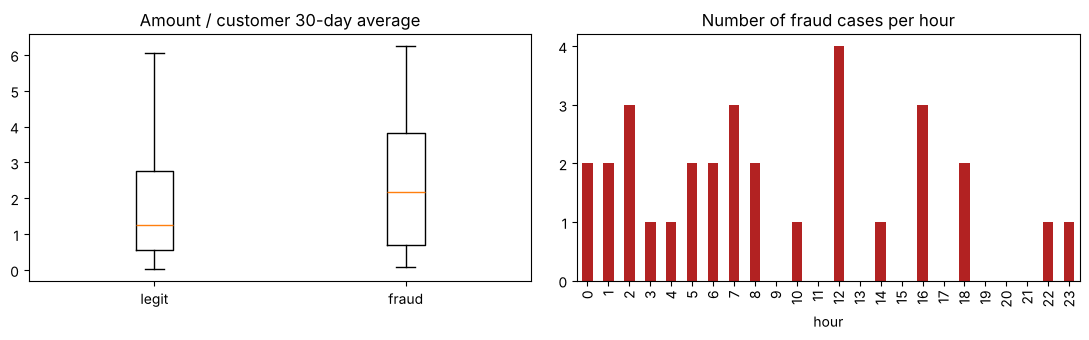

In [5]:
import matplotlib.pyplot as plt

num_cols = ['amount_eur', 'customer_avg_amount_30d', 'account_age_days',
            'previous_transactions_24h', 'hour', 'device_age_days']
print('Median per class:')
display(df.groupby('fraud_flag')[num_cols].median().T.round(1))

# Amount compared with the customer's own normal amount
ratio = df['amount_eur'] / df['customer_avg_amount_30d']
print('Median amount / customer 30-day average:')
display(ratio.groupby(df['fraud_flag']).median().round(2))

# Fraud rate per hour band (night = 00:00-05:59)
night = df['hour'].between(0, 5)
print('Fraud rate (%) by night vs day:')
display((df.groupby(night)['fraud_flag'].mean()*100).round(2).rename(index={True: 'night 0-5h', False: 'day 6-23h'}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].boxplot([ratio[df.fraud_flag == 0].dropna(), ratio[df.fraud_flag == 1].dropna()], showfliers=False)
ax[0].set_xticks([1, 2], ['legit', 'fraud']); ax[0].set_title('Amount / customer 30-day average')
(df.groupby('hour')['fraud_flag'].sum()).plot.bar(ax=ax[1], color='firebrick')
ax[1].set_title('Number of fraud cases per hour'); ax[1].set_xlabel('hour')
plt.tight_layout(); plt.show()

**Interpretation.**
* **[Data fact]** The *absolute* amount differs only a little (median €70 vs €60), but fraud transactions are much larger **relative to the customer's own normal amount** (median ratio ≈ 2.2 vs ≈ 1.3), and fraud customers have a lower 30-day average (€35 vs €48). Fraud therefore looks like "unusual for *this* customer" rather than "large in general". → this motivates the **engineered ratio feature** in Phase 3.
* **[Data fact]** Fraud happens relatively more at night (fraud rate ≈ 1.4 % at 00–06h vs ≈ 0.8 % during the day). → motivates a **night flag**.
* **[Data fact]** Account age and device age are *not* lower for fraud (medians are even higher), and `previous_transactions_24h` has the same median. So the typical "new account / new device" story is **not** supported by this data — a challenge to a common assumption.

### Two evidenced findings and two limitations
**Findings**
1. Fraud is rare (0.97 %, 31 cases) and two columns (`chargeback_confirmed_after_60d`, `post_investigation_loss_eur`) perfectly reveal the label → must be excluded; accuracy is meaningless.
2. The strongest visible signal is relative: amount compared with the customer's own 30-day average, plus night-time hours; absolute amount, account age and device age separate the classes poorly.

**Limitations**
1. **Only 31 fraud cases.** Any metric (recall, precision) will be very unstable: one extra fraud caught moves recall by ≈ 3 percentage points. Conclusions must be cautious.
2. **No timestamp/date.** I cannot do a time-based split or check whether fraud patterns change over time; real deployment would score *future* transactions. Review capacity, review cost and customer-friction cost are also not in the data (handled as assumptions).

**Effect on Phase 1:** the business framing (rank under limited capacity) is **confirmed**; the target is refined to "chargeback confirmed after 60 days", and the 50 % recall target is flagged as possibly optimistic given the weak signals.

## Phase 3 — Data Preparation: three justified decisions
For EACH insight: evidence → technique → before/after verification → interpretation → next decision. Consider identifiers, leakage, duplicate keys, suspicious values, categories, date parsing and feature engineering. Explain why you retain, delete or combine variables. **Do not use the target or post-outcome fields as predictors.**

**Important design choice [Choice]:** steps that do *not learn anything from the data* (removing duplicates, fixing spelling, marking impossible values, computing a ratio) are done here on the whole dataset. Steps that *learn* from the data (median imputation, scaling, one-hot categories) are put inside a scikit-learn `Pipeline` in Phase 4, so they are fitted on **training data only**. This prevents test information leaking into training.

In [6]:
# Add your preparation code below. Inspect before/after evidence.
# Make a copy first:
work = df.copy()

### Decision 1 — Remove exact duplicate rows
* **Evidence:** 3 exact duplicates; the 3 duplicated `transaction_id`s are full copies (2.2).
* **Technique:** `drop_duplicates()`. **Why:** a duplicated transaction would count twice in training and could end up in both the training and the test fold, which makes the evaluation look better than it is.

In [7]:
print('BEFORE: rows =', len(work), '| unique ids =', work['transaction_id'].nunique(), '| fraud =', work['fraud_flag'].sum())
work = work.drop_duplicates()
print('AFTER : rows =', len(work), '| unique ids =', work['transaction_id'].nunique(), '| fraud =', work['fraud_flag'].sum())
assert work['transaction_id'].is_unique

BEFORE: rows = 3203 | unique ids = 3200 | fraud = 31
AFTER : rows = 3200 | unique ids = 3200 | fraud = 31


* **Verification / interpretation:** 3,203 → 3,200 rows; every `transaction_id` is now unique, so the key is valid. No fraud case was lost (still 31).
* **Next decision:** with a clean key, decide which columns may be used as predictors.

### Decision 2 — Exclude the identifier and the post-investigation (leakage) fields
* **Evidence:** 2.3 showed `chargeback_confirmed_after_60d` equals the target exactly and `post_investigation_loss_eur` is > 0 only for fraud; both exist only *after* investigation. `transaction_id` is a label, not behaviour.
* **Technique:** keep these columns out of the predictor list. I **keep** `post_investigation_loss_eur` in a separate variable to measure "€ loss caught" in Phase 5 — it is **never** shown to the model.
* **Why it matters:** a model trained with them would look perfect in the notebook but cannot be used at the moment a payment is made.

In [8]:
target = 'fraud_flag'
leakage_cols = ['post_investigation_loss_eur', 'chargeback_confirmed_after_60d']
id_col = 'transaction_id'

# Demonstration of WHY: how well would the leakage column alone 'predict' fraud?
leak_pred = (work['chargeback_confirmed_after_60d'] == 1).astype(int)
print('Share of fraud "caught" by the leakage column alone:',
      (leak_pred[work[target] == 1] == 1).mean(), '-> a fake perfect model')

loss_eur = work['post_investigation_loss_eur']        # kept ONLY for evaluation in euros
excluded = [target, id_col] + leakage_cols
print('Columns BEFORE:', list(work.columns))
print('Columns that will never be predictors:', excluded)

Share of fraud "caught" by the leakage column alone: 1.0 -> a fake perfect model
Columns BEFORE: ['transaction_id', 'amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h', 'channel', 'country', 'hour', 'device_age_days', 'fraud_flag', 'post_investigation_loss_eur', 'chargeback_confirmed_after_60d']
Columns that will never be predictors: ['fraud_flag', 'transaction_id', 'post_investigation_loss_eur', 'chargeback_confirmed_after_60d']


* **Verification / interpretation:** the leakage column alone "catches" 100 % of fraud — proof that it is the answer, not a predictor. After this step only the 8 behavioural columns remain as candidate predictors.
* **Next decision:** clean those 8 columns (categories and impossible values).

### Decision 3 — Standardise `channel` and treat impossible account ages as missing
* **Evidence:** 6 spellings for 3 channels; 4 negative `account_age_days` (2.4).
* **Technique:**
  * `channel` → lower-case and strip spaces, so `APP`/`app` and `ONLINE`/`Online`/`online` merge. **Why:** they are the same channel; splitting them would spread the few fraud cases over more groups and weaken the evidence.
  * Negative account age → `NaN` (missing). **Why:** an account cannot be −22 days old; I do not know the true value, so deleting the rows (losing data) or setting them to 0 (inventing "brand-new account") are both worse than marking them missing. They are imputed later with the training median inside the pipeline. The 20 missing `amount_eur` values are handled the same way.

In [9]:
print('BEFORE channel:', work['channel'].value_counts().to_dict())
work['channel'] = work['channel'].str.strip().str.lower()
print('AFTER  channel:', work['channel'].value_counts().to_dict())

print('\nBEFORE negative account_age_days:', (work['account_age_days'] < 0).sum(),
      '| missing:', work['account_age_days'].isna().sum())
work.loc[work['account_age_days'] < 0, 'account_age_days'] = np.nan
print('AFTER  negative account_age_days:', (work['account_age_days'] < 0).sum(),
      '| missing:', work['account_age_days'].isna().sum())

BEFORE channel: {'app': 1017, 'online': 999, 'store': 596, 'Online': 246, 'APP': 230, 'ONLINE': 112}
AFTER  channel: {'online': 1357, 'app': 1247, 'store': 596}

BEFORE negative account_age_days: 4 | missing: 0
AFTER  negative account_age_days: 0 | missing: 4


* **Verification / interpretation:** `channel` now has exactly 3 values (app 1,247 / online 1,357 / store 596 — counts in output). Negative ages: 4 → 0; they now appear as 4 missing values to be imputed.
* **Next decision:** create features that express the relative patterns found in 2.5.

### Decision 4 — Feature engineering: amount relative to the customer's normal, and a night flag
* **Evidence:** 2.5: median ratio amount/30-day average ≈ 2.2 for fraud vs ≈ 1.3 for legit, while absolute amount differs little; fraud rate is higher at night.
* **Technique:**
  * `amount_to_avg_ratio = amount_eur / customer_avg_amount_30d`. **Why:** "€100" is normal for one customer and very unusual for another; the ratio captures *unusual for this customer*, which is how fraud analysts reason. A logistic regression cannot create such a division by itself.
  * `is_night = 1 if hour 0–5`. **Why:** `hour` as a plain number assumes 23h and 0h are far apart, while both are night. The flag expresses the business pattern simply. I keep `hour` as well.
  * The ratio is log-transformed (`np.log1p`) because it is extremely skewed (max ≈ 65); otherwise a few extreme values would dominate the model.
* **Leakage check:** both features use only information available at the payment moment (under the assumption in Phase 1 that the 30-day average excludes the current transaction).

In [10]:
work['amount_to_avg_ratio'] = np.log1p(work['amount_eur'] / work['customer_avg_amount_30d'])
work['is_night'] = work['hour'].between(0, 5).astype(int)

# Verification: do the new features separate the classes?
check = work.groupby(target).agg(
    median_log_ratio=('amount_to_avg_ratio', 'median'),
    median_raw_ratio=('amount_to_avg_ratio', lambda s: np.expm1(s.median())),
    night_share_pct=('is_night', lambda s: 100 * s.mean()))
display(check.round(2))
print('Missing ratio values (from missing amount):', work['amount_to_avg_ratio'].isna().sum())

,median_log_ratio,median_raw_ratio,night_share_pct
fraud_flag,,,
0,0.82,1.26,24.01
1,1.16,2.18,35.48


Missing ratio values (from missing amount): 20


* **Verification / interpretation:** the ratio separates the classes more clearly than raw amount (median ≈ 2.2× vs ≈ 1.3× the customer's normal), and fraud occurs at night more often than legit transactions (≈ 35 % vs ≈ 24 %). The 20 missing amounts give 20 missing ratios, which the pipeline imputes. Whether these features *really* help is tested in Phase 4 (model with vs without them) — not just assumed.
* **Next decision:** define the final predictor set and move to modelling.

In [11]:
num_features = ['amount_eur', 'customer_avg_amount_30d', 'account_age_days',
                'previous_transactions_24h', 'hour', 'device_age_days',
                'amount_to_avg_ratio', 'is_night']
cat_features = ['channel', 'country']
features = num_features + cat_features
assert not set(features) & set(excluded), 'leakage column in features!'
print('Final predictors:', features)
print('Excluded        :', excluded)
display(work[features].isna().sum())

Final predictors: ['amount_eur', 'customer_avg_amount_30d', 'account_age_days', 'previous_transactions_24h', 'hour', 'device_age_days', 'amount_to_avg_ratio', 'is_night', 'channel', 'country']
Excluded        : ['fraud_flag', 'transaction_id', 'post_investigation_loss_eur', 'chargeback_confirmed_after_60d']


amount_eur                   20
customer_avg_amount_30d       0
account_age_days              4
previous_transactions_24h     0
hour                          0
device_age_days               0
amount_to_avg_ratio          20
is_night                      0
channel                       0
country                       0
dtype: int64

### Preparation decision log
| Phase 2 finding | Technique and reason | Verification | Risk | Next decision |
|---|---|---|---|---|
| 3 exact duplicate rows; 3 repeated `transaction_id`s (2.2) | `drop_duplicates()` — avoid double counting and the same row in train and test | 3,203 → 3,200 rows, ID unique, still 31 frauds | Low: rows were identical copies | Choose allowed predictors |
| `chargeback_confirmed_after_60d` = target; loss > 0 only for fraud; both post-investigation (2.3) | Exclude both + `transaction_id` from predictors; keep loss only for € evaluation | Leakage column alone "catches" 100 % fraud → proof; assertion that no excluded column is a feature | Hidden leakage in other columns if they were computed after the payment (assumption on 30-day avg) | Clean remaining predictors |
| 6 spellings of `channel`; 4 negative account ages; 20 missing amounts (2.4) | Lower-case channel; negative age → NaN; median imputation **inside pipeline** (train only) | 3 channel values; 0 negative ages; NaNs counted | Median imputation slightly smooths extremes; missingness not informative here (no fraud among them) | Build features |
| Fraud = unusual *for this customer* and at night (2.5) | Engineer `amount_to_avg_ratio` (log) and `is_night` | Ratio medians 2.2× vs 1.3×; night share 35 % vs 24 % | With 31 frauds the pattern may be partly chance | Test value in Phase 4 (with vs without) |

## Phase 4 — Modelling
Define the prediction moment and allowed predictors. Use a defensible train/test split (chronological for forecasting). Fit learned preprocessing on TRAINING data only. Compare a simple baseline with a candidate model. Explain your feature engineering and excluded fields.

**Prediction moment:** when the payment is made. **Allowed predictors:** the 10 features above. **Excluded:** target, ID, and the two post-investigation fields (Decision 2).

**Validation strategy [Choice] — stratified 5-fold cross-validation with out-of-fold predictions.**
* There is no date column, so a chronological split is not possible (limitation noted in Phase 2).
* A single 70/30 split would put only ≈ 9 fraud cases in the test set: one lucky or unlucky case would change recall by 11 points. With **5-fold cross-validation** every transaction is scored exactly once by a model that **did not see it** during training. So all 31 frauds are used for evaluation while the test data stays unseen.
* **Stratified** = each fold keeps ≈ 1 % fraud, so no fold ends up without fraud.
* The imputer, scaler and one-hot encoder sit **inside the Pipeline**, so in every fold they are fitted on the four training folds only (no leakage from the test fold).

**Models**
1. **Naive baseline – "flag nothing":** shows why accuracy is misleading.
2. **Business-rule baseline – "review the largest amounts first":** a free, explainable rule a fraud team could use today. The model must beat this to be worth it.
3. **Candidate – Logistic Regression** (`class_weight='balanced'`). **Why:** simple, fast, works on small data, gives a probability score to rank transactions, and its coefficients can be explained to analysts. `class_weight='balanced'` makes each of the 31 fraud cases count as heavily as ≈ 100 legitimate ones, so the model does not simply ignore fraud. A more complex model (e.g. random forest) is not justified with only 31 positive cases — it would mainly memorise them.
4. **Iteration check:** the same logistic regression **without** the two engineered features, to test whether Decision 4 actually adds value.
5. **Iteration 2 (added after seeing the first results, see below):** a *reduced* logistic regression with only the two engineered features.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score

X = work[features]
y = work[target].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # fixed seed -> reproducible

def make_model(num_cols, cat_cols):
    # numeric: fill missing with TRAIN median, then scale (needed for logistic regression)
    # categorical: one-hot encode, unseen categories ignored
    steps = [('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                               ('scale', StandardScaler())]), num_cols)]
    if cat_cols:
        steps.append(('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols))
    prep = ColumnTransformer(steps)
    return Pipeline([('prep', prep),
                     ('model', LogisticRegression(class_weight='balanced', max_iter=1000))])

# Check that every fold contains fraud
for i, (tr, te) in enumerate(cv.split(X, y), 1):
    print(f'fold {i}: train fraud = {y[tr].sum()}, test fraud = {y[te].sum()}, test rows = {len(te)}')

fold 1: train fraud = 25, test fraud = 6, test rows = 640
fold 2: train fraud = 25, test fraud = 6, test rows = 640
fold 3: train fraud = 25, test fraud = 6, test rows = 640
fold 4: train fraud = 25, test fraud = 6, test rows = 640
fold 5: train fraud = 24, test fraud = 7, test rows = 640


In [13]:
# 1) Naive baseline: predict 'no fraud' for everybody
naive_pred = np.zeros_like(y)
print('Naive baseline accuracy :', round(accuracy_score(y, naive_pred), 4))
print('Naive baseline fraud caught:', int(naive_pred[y == 1].sum()), 'of', y.sum())

# 2) Business-rule baseline: score = amount (missing amount -> lowest priority)
rule_score = work['amount_eur'].fillna(0).values

# 3) Candidate: logistic regression with engineered features (out-of-fold probabilities)
cand_score = cross_val_predict(make_model(num_features, cat_features), X, y,
                               cv=cv, method='predict_proba')[:, 1]

# 4) Iteration: same model WITHOUT engineered features
base_num = [c for c in num_features if c not in ['amount_to_avg_ratio', 'is_night']]
noeng_score = cross_val_predict(make_model(base_num, cat_features), work[base_num + cat_features], y,
                                cv=cv, method='predict_proba')[:, 1]
# 5) Iteration 2: reduced model with only the engineered features (motivated below)
small_features = ['amount_to_avg_ratio', 'is_night']
small_score = cross_val_predict(make_model(small_features, []), work[small_features], y,
                                cv=cv, method='predict_proba')[:, 1]
print('Out-of-fold scores computed for', len(cand_score), 'transactions')

Naive baseline accuracy : 0.9903
Naive baseline fraud caught: 0 of 31


Out-of-fold scores computed for 3200 transactions


**How the comparison works.** Every approach gives a *score*; the business then reviews the top-k % highest scores. So I compare at a fixed capacity:
* **recall@k** = share of all 31 frauds inside the reviewed top-k,
* **precision@k** = share of reviewed transactions that are fraud,
* **false alarms** = legitimate customers reviewed,
* **€ caught** = share of total fraud loss inside the top-k (using `post_investigation_loss_eur`, evaluation only).

Two threshold-free summaries are added: **ROC-AUC** (0.5 = random) and **PR-AUC / average precision** (random ≈ fraud rate ≈ 0.01). PR-AUC is the more honest one for rare events.

In [14]:
def at_capacity(score, cap):
    # Review the top `cap` share of transactions with the highest score
    k = int(round(cap * len(score)))
    top = np.argsort(-score, kind='stable')[:k]
    flagged = np.zeros(len(score), dtype=bool); flagged[top] = True
    tp = int((flagged & (y == 1)).sum())
    return {'reviews': k, 'fraud_caught': tp, 'missed_fraud': int(y.sum() - tp),
            'false_alarms': k - tp,
            'recall_%': round(100 * tp / y.sum(), 1),
            'precision_%': round(100 * tp / k, 1),
            'loss_caught_%': round(100 * loss_eur.values[flagged].sum() / loss_eur.sum(), 1)}

scores = {'Rule: largest amount': rule_score,
          'LogReg without engineered feats': noeng_score,
          'LogReg candidate': cand_score,
          'LogReg reduced (iteration 2)': small_score}
rng = np.random.default_rng(42)
scores_with_random = {'Random review': rng.random(len(y)), **scores}

summary = pd.DataFrame({name: {'ROC_AUC': round(roc_auc_score(y, s), 3),
                               'PR_AUC': round(average_precision_score(y, s), 3),
                               **at_capacity(s, 0.05)}
                        for name, s in scores_with_random.items()}).T
print('Comparison at 5 % review capacity (out-of-fold, all 3,200 transactions):')
display(summary)

Comparison at 5 % review capacity (out-of-fold, all 3,200 transactions):


,ROC_AUC,PR_AUC,reviews,fraud_caught,missed_fraud,false_alarms,recall_%,precision_%,loss_caught_%
Random review,0.427,0.008,160.0,0.0,31.0,160.0,0.0,0.0,0.0
Rule: largest amount,0.556,0.012,160.0,2.0,29.0,158.0,6.5,1.2,26.3
LogReg without engineered feats,0.520,0.015,160.0,1.0,30.0,159.0,3.2,0.6,11.7
LogReg candidate,0.564,0.019,160.0,1.0,30.0,159.0,3.2,0.6,11.7
LogReg reduced (iteration 2),0.582,0.015,160.0,2.0,29.0,158.0,6.5,1.2,7.9


In [15]:
# Stability: how much does the candidate vary between folds? (recall in top 5 % of each test fold)
rows = []
for i, (tr, te) in enumerate(cv.split(X, y), 1):
    for name, s in scores.items():
        st, yt = s[te], y[te]
        k = int(round(0.05 * len(te)))
        caught = yt[np.argsort(-st, kind='stable')[:k]].sum()
        rows.append({'fold': i, 'model': name, 'fraud_in_fold': yt.sum(), 'caught_top5%': caught})
fold_df = pd.DataFrame(rows).pivot(index='fold', columns='model', values='caught_top5%')
fold_df['fraud_in_fold'] = pd.DataFrame(rows).groupby('fold')['fraud_in_fold'].first()
display(fold_df)

model,LogReg candidate,LogReg reduced (iteration 2),LogReg without engineered feats,Rule: largest amount,fraud_in_fold
fold,,,,,
1,0,0,0,1,6
2,0,1,0,0,6
3,0,1,1,0,6
4,1,0,1,1,6
5,0,0,0,0,7


**Why iteration 2?** The full candidate estimates 17 coefficients from only ≈ 25 fraud cases per training fold. A common rule of thumb for logistic regression is **≈ 10 events (frauds) per estimated coefficient**; with 25 frauds that means room for only 2–3 predictors. Too many predictors on so few events lets the model fit noise (overfitting). The coefficients (5.4) also show that `amount_eur`, `customer_avg_amount_30d` and the ratio overlap strongly. So I went back to the evidence of Phase 2/3 and built a reduced model with only the two features that showed the clearest separation there. This is a choice made *before* looking at the reduced model's test result, based on the data-size argument.

**Is the difference real or luck?** With 31 frauds, results depend on how the folds happen to be cut. Below I repeat the cross-validation with 5 different random fold assignments (seeds) and compare the average.

In [16]:
stab = []
for seed in [1, 2, 3, 4, 5]:
    cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    s_full = cross_val_predict(make_model(num_features, cat_features), X, y, cv=cv_s, method='predict_proba')[:, 1]
    s_small = cross_val_predict(make_model(small_features, []), work[small_features], y, cv=cv_s, method='predict_proba')[:, 1]
    for name, s in [('Rule: largest amount', rule_score), ('LogReg candidate', s_full), ('LogReg reduced (iteration 2)', s_small)]:
        stab.append({'seed': seed, 'model': name, 'ROC_AUC': roc_auc_score(y, s), 'PR_AUC': average_precision_score(y, s),
                     'caught@5%': at_capacity(s, 0.05)['fraud_caught'], 'caught@10%': at_capacity(s, 0.10)['fraud_caught'],
                     'caught@20%': at_capacity(s, 0.20)['fraud_caught']})
stab = pd.DataFrame(stab)
display(stab.groupby('model')[['ROC_AUC', 'PR_AUC', 'caught@5%', 'caught@10%', 'caught@20%']].agg(['mean', 'min', 'max']).round(3))

ROC_AUC               PR_AUC                \
                                mean    min    max   mean    min    max   
model                                                                     
LogReg candidate               0.564  0.505  0.608  0.015  0.011  0.026   
LogReg reduced (iteration 2)   0.587  0.563  0.601  0.015  0.013  0.016   
Rule: largest amount           0.556  0.556  0.556  0.012  0.012  0.012   

                             caught@5%         caught@10%         caught@20%  \
                                  mean min max       mean min max       mean   
model                                                                          
LogReg candidate                   1.8   0   4        4.4   4   5        8.6   
LogReg reduced (iteration 2)       2.0   1   3        6.2   5   8       10.8   
Rule: largest amount               2.0   2   2        4.0   4   4        5.0   

                                      
                             min max  
model                                 
LogReg candidate               7  10  
LogReg reduced (iteration 2)   8  12  
Rule: largest amount           5   5

### Modelling interpretation (evidence from the outputs above)
* **Naive baseline:** 99.03 % accuracy but **0 of 31 frauds caught** → confirms that accuracy cannot be the success measure.
* **Noise level:** the *random* score reached ROC-AUC 0.43, while its expected value is 0.50. With only 31 frauds, differences of a few hundredths in AUC can be pure chance, so I read small differences with caution.
* **Full candidate vs rule:** ROC-AUC 0.564 vs 0.556 and PR-AUC 0.019 vs 0.012, but at 5 % capacity the candidate catches **1** fraud and the rule **2**. The full candidate is **not** clearly better than the free rule.
* **Effect of feature engineering (Decision 4):** without the engineered features ROC-AUC drops to 0.520 (≈ random), so the ratio/night features carry most of the little signal there is.
* **Iteration 2 (reduced model):** across 5 different fold seeds the reduced model is the most stable (ROC-AUC 0.563–0.601, mean 0.587) and catches on average **2.0 / 6.2 / 10.8** frauds at 5 / 10 / 20 % capacity, versus **2 / 4 / 5** for the rule and 1.8 / 4.4 / 8.6 for the full candidate. Fewer predictors = less overfitting, which matches the events-per-variable argument.
* **Overall:** every approach is only slightly better than random. PR-AUC ≈ 0.015 means roughly 1.5 % of high-scored transactions are fraud, against 0.97 % when picking at random. **Next decision:** evaluate what this means for the business in Phase 5, with the reduced model as best candidate.

## Phase 5 — Evaluation
Report model vs baseline on held-out observations. Interpret relevant classification errors or forecasting MAE by business segment. Compare with your Phase 1 success criterion and discuss whether that criterion is realistic. If a required cost/impact is unavailable, state the assumption or request more data.

### 5.1 Threshold consequences: what happens at different review capacities?
**Plan:** since the real capacity is unknown, show the trade-off for 2 %, 5 %, 10 % and 20 %. Each row is a possible "threshold" for the business.

reviews  fraud_caught  missed_fraud  \
Rule: largest amount         2%      64.0           0.0          31.0   
                             5%     160.0           2.0          29.0   
                             10%    320.0           4.0          27.0   
                             20%    640.0           5.0          26.0   
LogReg candidate             2%      64.0           1.0          30.0   
                             5%     160.0           1.0          30.0   
                             10%    320.0           4.0          27.0   
                             20%    640.0           8.0          23.0   
LogReg reduced (iteration 2) 2%      64.0           1.0          30.0   
                             5%     160.0           2.0          29.0   
                             10%    320.0           6.0          25.0   
                             20%    640.0          11.0          20.0   

                                  false_alarms  recall_%  precision_%  \
Rule: largest amount         2%           64.0       0.0          0.0   
                             5%          158.0       6.5          1.2   
                             10%         316.0      12.9          1.2   
                             20%         635.0      16.1          0.8   
LogReg candidate             2%           63.0       3.2          1.6   
                             5%          159.0       3.2          0.6   
                             10%         316.0      12.9          1.2   
                             20%         632.0      25.8          1.2   
LogReg reduced (iteration 2) 2%           63.0       3.2          1.6   
                             5%          158.0       6.5          1.2   
                             10%         314.0      19.4          1.9   
                             20%         629.0      35.5          1.7   

                                  loss_caught_%  
Rule: largest amount         2%             0.0  
                             5%            26.3  
                             10%           44.8  
                             20%           50.2  
LogReg candidate             2%            11.7  
                             5%            11.7  
                             10%           20.3  
                             20%           26.4  
LogReg reduced (iteration 2) 2%             5.4  
                             5%             7.9  
                             10%           31.2  
                             20%           55.5

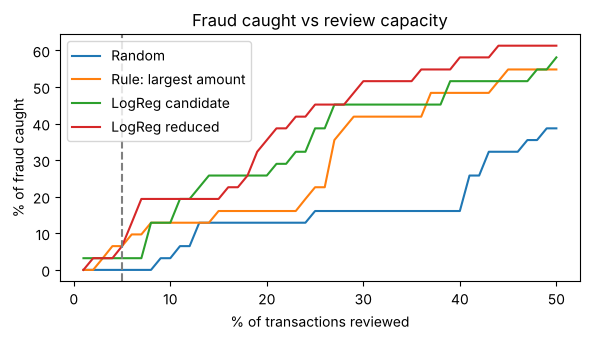

In [17]:
caps = [0.02, 0.05, 0.10, 0.20]
tradeoff = pd.concat({name: pd.DataFrame({f'{int(c*100)}%': at_capacity(s, c) for c in caps}).T
                      for name, s in [('Rule: largest amount', rule_score), ('LogReg candidate', cand_score),
                                       ('LogReg reduced (iteration 2)', small_score)]})
display(tradeoff)

# Precision-at-capacity curve for a visual comparison
fig, ax = plt.subplots(figsize=(6, 3.5))
grid = np.linspace(0.01, 0.5, 50)
for name, s in [('Random', scores_with_random['Random review']), ('Rule: largest amount', rule_score),
                ('LogReg candidate', cand_score), ('LogReg reduced', small_score)]:
    ax.plot(grid * 100, [at_capacity(s, c)['recall_%'] for c in grid], label=name)
ax.axvline(5, ls='--', c='grey'); ax.set_xlabel('% of transactions reviewed'); ax.set_ylabel('% of fraud caught')
ax.set_title('Fraud caught vs review capacity'); ax.legend(); plt.tight_layout(); plt.show()

### 5.2 Errors in business terms at the 5 % capacity
**Plan:** translate the confusion matrix into customers and euros.
* **False positive (false alarm):** a legitimate customer whose payment is reviewed → delay/annoyance, possible churn, plus analyst time.
* **False negative (missed fraud):** fraud that is not reviewed → the wallet pays the chargeback (the € in `post_investigation_loss_eur`).

In [18]:
# Shown for the best-performing model from Phase 4 (reduced logistic regression)
best_score = small_score
k = int(round(0.05 * len(y)))
flag = np.zeros(len(y), dtype=bool); flag[np.argsort(-best_score, kind='stable')[:k]] = True
cm = pd.crosstab(pd.Series(y, name='actual'), pd.Series(flag.astype(int), name='reviewed (top 5%)'))
display(cm)
total_loss = loss_eur.sum()
caught_loss = loss_eur.values[flag & (y == 1)].sum()
print(f'Total fraud loss in data      : EUR {total_loss:,.2f}')
print(f'Loss in reviewed transactions : EUR {caught_loss:,.2f} ({100*caught_loss/total_loss:.1f} %)')
print(f'Loss still missed             : EUR {total_loss-caught_loss:,.2f}')
print(f'Legitimate customers reviewed : {int((flag & (y == 0)).sum())} -> about '
      f'{(flag & (y == 0)).sum() / max((flag & (y == 1)).sum(),1):.0f} false alarms per fraud found')

reviewed (top 5%),0,1
actual,,
0,3011,158
1,29,2


Total fraud loss in data      : EUR 2,778.46
Loss in reviewed transactions : EUR 220.59 (7.9 %)
Loss still missed             : EUR 2,557.87
Legitimate customers reviewed : 158 -> about 79 false alarms per fraud found


### 5.3 Segments: does the model work equally well for every channel and country?
**Plan:** for the reduced model at the 5 % capacity, count fraud caught per segment. **Caution:** segments contain only 3–15 frauds, so differences are indicative, not proof.

In [19]:
seg = work[['channel', 'country']].copy()
seg['fraud'] = y; seg['reviewed'] = flag; seg['caught'] = flag & (y == 1)
for col in ['channel', 'country']:
    t = seg.groupby(col).agg(transactions=('fraud', 'size'), fraud=('fraud', 'sum'),
                             reviewed=('reviewed', 'sum'), caught=('caught', 'sum'))
    t['recall_%'] = (100 * t['caught'] / t['fraud']).round(0)
    t['review_share_%'] = (100 * t['reviewed'] / t['transactions']).round(1)
    display(t)

,transactions,fraud,reviewed,caught,recall_%,review_share_%
channel,,,,,,
app,1247,9,66,1,11.0,5.3
online,1357,14,65,1,7.0,4.8
store,596,8,29,0,0.0,4.9


,transactions,fraud,reviewed,caught,recall_%,review_share_%
country,,,,,,
BE,522,5,21,1,20.0,4.0
DE,569,7,32,0,0.0,5.6
ES,515,7,33,0,0.0,6.4
FR,518,4,26,0,0.0,5.0
NL,534,3,25,0,0.0,4.7
UK,542,5,23,1,20.0,4.2


### 5.4 What does the model look at? (coefficients)
**Plan:** fit the candidate once on all data *only to explain it* (not to evaluate it). Positive coefficient = higher fraud score. Numeric features are scaled, so coefficients are comparable.

In [20]:
final_model = make_model(num_features, cat_features).fit(X, y)
names = final_model.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(final_model.named_steps['model'].coef_[0], index=names).sort_values()
display(coefs.round(2).to_frame('coefficient (full candidate)'))

small_model = make_model(small_features, []).fit(work[small_features], y)
display(pd.Series(small_model.named_steps['model'].coef_[0], index=small_features).round(2).to_frame('coefficient (reduced)'))

,coefficient (full candidate)
num__amount_eur,-0.75
num__hour,-0.52
cat__channel_app,-0.37
cat__country_NL,-0.20
cat__country_FR,-0.19
cat__country_BE,-0.17
num__is_night,-0.15
cat__country_UK,-0.10
cat__channel_online,-0.07
num__account_age_days,0.12


,coefficient (reduced)
amount_to_avg_ratio,0.31
is_night,0.23


### 5.5 Evaluation interpretation and business decision

**Comparison with the Phase 1 success criterion.**
| Criterion (Phase 1) | Rule: largest amount | Reduced LogReg (best) | Met? |
|---|---|---|---|
| ≥ 50 % of fraud caught at 5 % capacity | 6.5 % (2/31) | 6.5 % (2/31) | **No** |
| Clearly better than the rule | — | equal at 5 %; better at 10–20 % in cases (6 vs 4, 11 vs 5) | **Partly, only at higher capacity** |
| € loss caught at 5 % | 26.3 % | 7.9 % | Rule better |

**Errors in business terms (5 % capacity, reduced model):** 160 reviews find **2 frauds** and create **158 false alarms** — about **79 legitimate customers bothered for every fraud found** — while **29 frauds (≈ €2,558 of €2,778 loss) are still missed**. At 20 % capacity the model finds 11 frauds (35.5 %, 55.5 % of the loss), but needs 640 reviews and 629 false alarms. Since a review costs analyst time and customer friction, and the average fraud loss is only ≈ €90, it is very doubtful that this many reviews pay for themselves. **[Assumption]** No cost per review is given. A simple break-even check: at 5 % capacity the model catches €220.59 with 160 reviews (≈ **€1.38 per review**); at 20 % it catches ≈ €1,542 with 640 reviews (≈ **€2.41 per review**). If one manual review costs more than that (a few minutes of analyst time almost certainly does), the reviews cost more than the fraud they stop — and that ignores the customer friction of the false alarms. **The real review cost must be requested from the business to confirm this.**

**Interesting trade-off:** the amount rule catches *fewer cases* but *more euros* at low capacity (26 % of the loss at 5 %), because the largest frauds are large transactions. The model targets "unusual for this customer", which catches more cases but smaller ones. Which matters more (number of victims vs euros) is a business choice that is not specified in the scenario.

**Segments:** the reduced model spreads reviews evenly (4–6.4 % of transactions in every channel and country), so no channel or country is unfairly overloaded with reviews. Recall per segment is based on 0–1 caught frauds and 3–14 frauds per segment, so **no reliable segment conclusion can be drawn** — this is a data-size limitation, not evidence that the model works equally well everywhere.

**Coefficients:** in the full model `amount_eur` (−0.75), `customer_avg_amount_30d` (+0.37) and the ratio (+1.11) work against each other, and `is_night` gets a *negative* sign despite Phase 2 showing more fraud at night. This is a sign of overlapping predictors and overfitting, supporting iteration 2. The reduced model has the expected, explainable signs: higher ratio (+0.31) and night (+0.23) → higher fraud score.

**Is the Phase 1 criterion realistic?** With the current 8 behavioural variables, no: the best observed recall@5 % is 6.5 %. The 50 % target was set before seeing the data and is not achievable with these features. A realistic next criterion is first to prove that the model beats the rule in a pilot with more data, before setting a fixed recall target.

**Limitations:** (1) only 31 frauds → wide uncertainty on all numbers; (2) no timestamp → no test on *future* transactions, possible concept drift unknown; (3) costs of review and friction unknown; (4) label arrives only after 60 days; (5) assumption that the 30-day average and 24h count exclude the current transaction is unverified.

**Decision: DO NOT DEPLOY as a review-selection tool — return to Phase 1/2 and collect more data.** The model does not meet the success criterion and is not convincingly better than a free, explainable rule at the realistic 5 % capacity. Deploying it would mostly create false alarms for legitimate customers. The current amount-based rule remains the better default for protecting euros. The reduced model is worth testing again in **shadow mode** (see Phase 6) once more labelled fraud cases and stronger features (e.g. device/IP changes, merchant type, failed login attempts, transaction timestamps) are available.

## Phase 6 — Deployment proposal (design only)
Specify who uses the prediction, when it runs, what action it supports, a human override, monitoring metric, feedback/refresh trigger and a condition for pausing use. A diagram or 6–8 sentences is sufficient. No production system required.

Because the decision is *do not deploy yet*, this is the design for the **next iteration: a shadow-mode pilot**, in which the model scores transactions but does not influence any decision until it has proven itself.

| Element | Design |
|---|---|
| **User** | Fraud-operations team lead (owns the queue) and fraud analysts; data analyst maintains the model. |
| **When it runs** | Real-time at the payment moment, using only the predictors available then (amount, 30-day average, hour). Scores are stored; in shadow mode they are **not** shown in the queue. |
| **Action supported** | Ranking the manual review queue: the top-k % (k = actual capacity agreed with operations) would be reviewed. The model never blocks a payment by itself. |
| **Human oversight / override** | Analysts make the final decision on every reviewed transaction and can add or remove transactions from the queue; existing rules (e.g. largest amounts) stay active in parallel. Overrides are logged with a reason. |
| **Monitoring** | Monthly, once chargeback labels arrive (≈ 60 days delay): recall@capacity and € loss caught versus the amount rule; false alarms per fraud found; review share per channel/country (no segment should get a much higher review rate); share of missing amounts and the distribution of the ratio feature (data drift). |
| **Feedback / refresh trigger** | Retrain when ≥ 100 new confirmed fraud cases are available, or every 6 months, or when the ratio/hour distribution shifts clearly from the training data. Investigation outcomes feed back as new labels (but never as predictors). |
| **Move from shadow to live** | Only if over at least 3 months the model catches more fraud **and** at least as much € as the rule, at the same capacity. |
| **Pause / stop condition** | Pause if recall@capacity falls below the amount rule for two consecutive months, if false alarms per fraud found rise above an agreed limit (e.g. 50), if a channel/country gets more than double the average review rate, or if an input field breaks (e.g. > 5 % missing amounts or new channel values). |

**Data to collect for the next iteration:** a transaction timestamp (for a time-based validation), more fraud cases (longer period), the cost of a review and of a false alarm, and richer pre-payment features (device/IP change, merchant category, login failures).

## Final group decision + individual accountability
**Group decision: Revisit earlier CRISP-DM phase / Do not deploy yet.**
Evidence: the best model catches 2 of 31 frauds (6.5 %) at the assumed 5 % review capacity — the same as the free amount rule and far below the ≥ 50 % target — with ≈ 79 false alarms per fraud found (5.2). Its ROC-AUC (≈ 0.58–0.59 over 5 seeds) is close to the random-noise range seen in Phase 4. It only outperforms the rule at higher capacities (20 %: 11 vs 5 frauds), which would require ≈ 630 false alarms. The data contains too few fraud cases and too weak pre-payment signals; we return to Phase 1/2 (agree capacity and costs, collect timestamps, more cases and stronger features) and test the reduced model in shadow mode.

**Individual — Aäron Bos**
* **Preparation choice:** I excluded `chargeback_confirmed_after_60d` and `post_investigation_loss_eur` as predictors, because they only exist after the investigation; the chargeback column alone "caught" 100 % of fraud, which proves it is the answer and not a signal. I kept the loss column only to measure euros caught in the evaluation.
* **Model finding:** the full logistic regression with 17 coefficients overfitted on ≈ 25 frauds per training fold (unstable, partly illogical signs). Reducing it to the two engineered features (amount relative to the customer's 30-day average and a night flag) gave more stable results and the best case recall at 10–20 % capacity, showing that a simpler model can be better on rare-event data.
* **Business implication:** with the current data, a model would mainly bother legitimate customers (≈ 79 per fraud found at 5 % capacity) without catching more fraud than a simple "largest amount" rule, which also protects more euros. The business should keep the rule, supply the real review capacity and review costs, and collect richer data before investing in a fraud model.